In [1]:
import pandas as pd
import numpy as np

# Round 1: 


1. Dryland flax

The order book shows a stale state of bids and asks for Dryland Flax. Use this to determine your own strategy and order input. Any Dryland Flax you acquire will be sold directly after the auction closes for 30 XIRECs per piece.

2. Ember Mushroom

This order book shows a stale state of bids and asks for Ember Mushroom. Use this to determine your own strategy and order input. Trading fees per volume apply: 0.05 XIRECs for buying and 0.05 XIRECs for selling. Any Ember Mushroom you acquire will be sold directly after the auction closes for 20 XIRECs per piece.

**Auction rules**: 

You have to submit a single limit order (price, quantity). 
When the auction ends, the exchange selects a single clearing price that: 
1. maximizes total traded volume, then 
2. breaks ties by choosing the higher price. 

All bids with price ≥ clearing price and asks with price ≤ clearing price execute at the clearing price. Allocation is price priority, then time priority. Since you are last to submit, you are last in line at any price level you join. 

**Guaranteed buyback after the auction**:

You will not trade these products in continuous trading. Instead, right after the auction the Merchant Guild will buy any inventory you trade at a fixed price: 
- DRYLAND_FLAX: 30 per unit (no fees) 
- EMBER_MUSHROOM: 20 per unit (fee: 0.10 per unit traded) 

**Submit your orders**

Choose a bid price and quantity for each product to maximize your profit. Enter your orders directly in the Manual Challenge Overview window and click the “Submit” button. You can re-submit new orders until the end of the trading round. When the round ends, the last submitted orders will be executed. buy/sell price volume for each.

In [3]:
dryland_flax_data = [
    {"bid_volume": 30000, "bid_price": 30, "ask_price": 28, "ask_volume": 40000},
    {"bid_volume": 5000,  "bid_price": 29, "ask_price": 31, "ask_volume": 20000},
    {"bid_volume": 12000, "bid_price": 28, "ask_price": 32, "ask_volume": 20000},
    {"bid_volume": 28000, "bid_price": 27, "ask_price": 33, "ask_volume": 33000},
]

df_flax = pd.DataFrame(dryland_flax_data)
print('--------------------')
print(df_flax)
print('--------------------')

data = [
    {"bid_volume": 43000, "bid_price": 20, "ask_price": 12, "ask_volume": 20000},
    {"bid_volume": 17000, "bid_price": 19, "ask_price": 13, "ask_volume": 25000},
    {"bid_volume": 6000,  "bid_price": 18, "ask_price": 14, "ask_volume": 35000},
    {"bid_volume": 5000,  "bid_price": 17, "ask_price": 15, "ask_volume": 6000},
    {"bid_volume": 10000, "bid_price": 16, "ask_price": 16, "ask_volume": 5000},
    {"bid_volume": 5000,  "bid_price": 15, "ask_price": 17, "ask_volume": 0},
    {"bid_volume": 10000, "bid_price": 14, "ask_price": 18, "ask_volume": 10000},
    {"bid_volume": 7000,  "bid_price": 13, "ask_price": 19, "ask_volume": 12000},
]

df_mushroom = pd.DataFrame(data)

print(df_mushroom)
print('--------------------')


--------------------
   bid_volume  bid_price  ask_price  ask_volume
0       30000         30         28       40000
1        5000         29         31       20000
2       12000         28         32       20000
3       28000         27         33       33000
--------------------
   bid_volume  bid_price  ask_price  ask_volume
0       43000         20         12       20000
1       17000         19         13       25000
2        6000         18         14       35000
3        5000         17         15        6000
4       10000         16         16        5000
5        5000         15         17           0
6       10000         14         18       10000
7        7000         13         19       12000
--------------------


In [4]:
def generate_baseline_table(df):
    """ Input: df with columns: bid_price, bid_volume, ask_price, ask_volume Output: DataFrame with: price | demand (>=P) | supply (<=P) | tradeable """ 
    # Get all unique price levels (from both bid + ask) 
    bids = df.dropna(subset=['bid_price'])['bid_price'] 
    asks = df.dropna(subset=['ask_price'])['ask_price'] 
     # Get all unique price levels
    prices = sorted(set(bids).union(set(asks))) 
    results = []
    for p in prices: 
    # Demand: sum of bid_volume where bid_price >= p 
        demand = df.loc[df['bid_price'] >= p, 'bid_volume'].sum() 
    # Supply: sum of ask_volume where ask_price <= p 
        supply = df.loc[df['ask_price'] <= p, 'ask_volume'].sum() 
    # Tradeable volume 
        tradeable = min(demand, supply) 
        results.append({ "price": p, "demand_ge_p": demand, "supply_le_p": supply, "tradeable": tradeable }) 
        
    baseline_df = pd.DataFrame(results).sort_values(by="price", ascending=False).reset_index(drop=True) 
    baseline_df['clearing_price'] = ( baseline_df['tradeable'] == baseline_df['tradeable'].max() ) 
    return baseline_df 
flax_table = generate_baseline_table(df_flax) 
print(flax_table.sort_values(by="tradeable", ascending=False)) 
mushroom_table = generate_baseline_table(df_mushroom) 
print(mushroom_table.sort_values(by="tradeable", ascending=False))

   price  demand_ge_p  supply_le_p  tradeable  clearing_price
5     28        47000        40000      40000            True
4     29        35000        40000      35000           False
3     30        30000        40000      30000           False
0     33            0       113000          0           False
1     32            0        80000          0           False
2     31            0        60000          0           False
6     27        75000            0          0           False
   price  demand_ge_p  supply_le_p  tradeable  clearing_price
5     15        86000        86000      86000            True
4     16        81000        91000      81000           False
6     14        96000        80000      80000           False
3     17        71000        91000      71000           False
2     18        66000       101000      66000           False
1     19        60000       113000      60000           False
7     13       103000        45000      45000           False
0     20

In [ ]:
def find_clearing_price(baseline_df):
    max_trade = baseline_df["tradeable"].max()
    
    candidates = baseline_df[baseline_df["tradeable"] == max_trade]
    
    # tie-break: higher price wins
    row = candidates.sort_values("price", ascending=False).iloc[0]
    
    return row["price"], row

def add_my_order(df, price, quantity, side="bid"):
    # Use np.nan instead of None to prevent comparison errors
    new_row = {
        "bid_price": price if side == "bid" else np.np.np.np.np.np.np.np.np.np.np.np.np.np.np.np.np.np.np.np.np.np.np.nan,
        "bid_volume": quantity if side == "bid" else 0,
        "ask_price": price if side == "ask" else np.np.nan,
        "ask_volume": quantity if side == "ask" else 0
    }
    return pd.concat([df, pd.DataFrame([new_row])], ignore_index=True)
    
def compute_my_fill(df, my_price, my_qty, clearing_price):
    if my_price < clearing_price:
        return 0

    # Total supply available at this clearing price
    total_supply = df.loc[df['ask_price'] <= clearing_price, 'ask_volume'].sum()

    # Demand that gets filled BEFORE you:
    # 1. Everyone bidding strictly more than you (Price Priority)
    demand_better_price = df.loc[df['bid_price'] > my_price, 'bid_volume'].sum()
    
    # 2. Everyone bidding the same price as you (Time Priority - you are last)
    # We subtract your own volume from the 'at price' total to find 'others'
    demand_same_price_others = df.loc[df['bid_price'] == my_price, 'bid_volume'].sum() - my_qty

    priority_demand = demand_better_price + demand_same_price_others

    # You get what is left over
    remaining_supply = max(0, total_supply - priority_demand)
    
    return min(my_qty, remaining_supply)

def build_execution_view(df, clearing_price, my_price=None, my_qty=None):
    df_exec = df.copy().reset_index(drop=True)

    # =========================
    # 1. ACTIVE FILTERING
    # =========================
    df_exec["bid_active"] = df_exec["bid_price"] >= clearing_price
    df_exec["ask_active"] = df_exec["ask_price"] <= clearing_price

    df_exec["participates"] = (
        df_exec["bid_active"].fillna(False) |
        df_exec["ask_active"].fillna(False)
    )

    df_exec["bid_exec_volume"] = df_exec["bid_volume"].where(df_exec["bid_active"], 0)
    df_exec["ask_exec_volume"] = df_exec["ask_volume"].where(df_exec["ask_active"], 0)

    # =========================
    # 2. SPLIT + SORT (NO MERGE EVER)
    # =========================
    bid_idx = df_exec[df_exec["bid_active"]].index
    ask_idx = df_exec[df_exec["ask_active"]].index

    bid_sorted = df_exec.loc[bid_idx].sort_values(
        by=["bid_price"],
        ascending=False
    )

    ask_sorted = df_exec.loc[ask_idx].sort_values(
        by=["ask_price"],
        ascending=True
    )

    # =========================
    # 3. TRADEABLE
    # =========================
    tradeable = min(
        bid_sorted["bid_exec_volume"].sum(),
        ask_sorted["ask_exec_volume"].sum()
    )

    # =========================
    # 4. CUMULATIVE FILL (INDEX SAFE)
    # =========================
    remaining = tradeable
    bid_fill = pd.Series(0, index=df_exec.index)

    for i in bid_sorted.index:
        v = df_exec.loc[i, "bid_exec_volume"]
        fill = min(v, remaining)
        bid_fill[i] = fill
        remaining -= fill

    remaining = tradeable
    ask_fill = pd.Series(0, index=df_exec.index)

    for i in ask_sorted.index:
        v = df_exec.loc[i, "ask_exec_volume"]
        fill = min(v, remaining)
        ask_fill[i] = fill
        remaining -= fill

    df_exec["cumulative_filled_bid_volume"] = bid_fill
    df_exec["cumulative_filled_ask_volume"] = ask_fill

    # =========================
    # 5. YOUR ORDER FLAG
    # =========================
    if my_price is not None:
        df_exec["is_my_order"] = (
            (df_exec["bid_price"] == my_price) |
            (df_exec["ask_price"] == my_price)
        )
    else:
        df_exec["is_my_order"] = False

    return df_exec
def simulate_strategy(df, my_price, my_qty, side="bid", resale_price=None, fee=0):
    # 1. Add your order first to see the full market state
    print('Before adding my order')
    print(df)
    print('--------------------')
    df_new = add_my_order(df, my_price, my_qty, side)
    
     # Allocation is price priority, then time priority. Since you are last to submit, you are last in line at any price level you join. 
    df_new = df_new.sort_values(by="bid_price", ascending=False).reset_index(drop=True)
    print('After adding my order')
    print(df_new)
    
    print('--------------------')
    print('Before adding my order, generating baseline')
    old_baseline = generate_baseline_table(df) 
    print(old_baseline.sort_values(by="price", ascending=False))

    # 2. Calculate the ACTUAL clearing price with your order included
    baseline = generate_baseline_table(df_new)
    baseline = baseline.sort_values(by="price", ascending=False).reset_index(drop=True)
    print('--------------------')
    print('After adding my order, generating baseline')
    print(baseline)
    clearing_price, _ = find_clearing_price(baseline)

    # 3. Compute your fill based on this new clearing price
    my_fill = compute_my_fill(df_new, my_price, my_qty, clearing_price)
    print('--------------------')
    # df after executing the clearing price 
    # baseline after executing the clearing price 
    execution_df = build_execution_view(
        df_new,
        clearing_price,
        my_price=my_price,
        my_qty=my_qty
    )
    print(execution_df)

    # 4. Calculate profit
    profit = my_fill * (resale_price - clearing_price - fee)

    return {
        "clearing_price": clearing_price,
        "filled_qty": my_fill,
        "profit": profit
    }

# result = simulate_strategy(
#     df_flax,
#     my_price=29,
#     my_qty=4999,
#     resale_price=30,
#     fee=0
# )

# print(result)


result = simulate_strategy(
    df_mushroom,
    my_price=20,
    my_qty=19999,
    resale_price=20,
    fee=0.1
)

print(result)


result = simulate_strategy(
    df_mushroom,
    my_price=19,
    my_qty=19999,
    resale_price=20,
    fee=0.1
)

print(result)

Before adding my order
   bid_volume  bid_price  ask_price  ask_volume
0       43000         20         12       20000
1       17000         19         13       25000
2        6000         18         14       35000
3        5000         17         15        6000
4       10000         16         16        5000
5        5000         15         17           0
6       10000         14         18       10000
7        7000         13         19       12000
--------------------
After adding my order
   bid_volume  bid_price  ask_price  ask_volume
0       43000         20       12.0       20000
1       19999         20        NaN           0
2       17000         19       13.0       25000
3        6000         18       14.0       35000
4        5000         17       15.0        6000
5       10000         16       16.0        5000
6        5000         15       17.0           0
7       10000         14       18.0       10000
8        7000         13       19.0       12000
--------------------
B

In [16]:
# max_profit = 0
# baseline = generate_baseline_table(df_mushroom)
# for i in range(12,21):
#     for j in range(baseline.iloc[0]['demand_ge_p'], baseline.iloc[0]['supply_le_p']):
#         result = simulate_strategy(
#             df_mushroom,
#             my_price=i,
#             my_qty=j,
#             resale_price=20,
#             fee=0.1)
#         if result['profit'] > max_profit:
#             max_profit = result['profit']
#             print(f"New max profit: {max_profit} at price {i} and quantity {j}")   
#             print(result)


# Round 2: Invest & expand


- You've been granted a substantial budget to expand your trading outpost. You have 50,000 XIRECs at your disposal to invest across three growth pillars: Research, Scale, and Speed.

- Investments in Research are directed toward quantitative research, data acquisition, machine learning infrastructure, backtesting systems, and related capabilities.

- Budget allocated to Scale supports traders, engineers, offices, exchange access, and other factors that allow your operations to expand.

- Investments in Speed are applied to technologies such as FPGA boards, colocation, RF towers, microwave links, and other latency-reducing infrastructure.

- This is a one-time opportunity and does not affect your algorithmic trading activities. Enter your submission below and click Submit to confirm.

## Details:

You are expanding your outpost into a true market making firm with a budget of `50 000` XIRECs. You need to allocate this budget across three pillars:

- **Research**
- **Scale**
- **Speed**

You choose percentages for each pillar between 0–100%. Total allocation cannot exceed 100%. Your final PnL (Profit and Loss) score is:

<aside>

PnL = (Research × Scale × Speed) − Budget_Used

</aside>

### **The pillars**

**Research** determines how strong your trading edge is. It grows **logarithmically** from `0` (for `0` invested) to `200 000`  (for `100` invested). The exact formula is `research(x) = 200_000 * np.log(1 + x) / np.log(1 + 100)`. Here, `np.log` is a python function from NumPy package for natural logarithm.

**Scale** determines how broadly you deploy your strategy across markets. It grows **linearly** from `0` (for `0` invested) to `7` (for `100` invested).

**Speed** determines how often you win the trades you target. It is **rank-based** across all players:

- Highest speed investment receives a `0.9` multiplier.
- Lowest receives `0.1`.
- Everyone in between is scaled linearly by rank, equal investments share the same rank.
- For example, if people invested `70, 70, 70, 50, 40, 40, 30`, they get the following ranks: `1, 1, 1, 4, 5, 5, 7`. First three players get `0.9` for hit rate multiplier, last player gets `0.1`, and everybody in between gets linearly scaled between top and bottom rank. Another example, if you have three players investing `95, 20, 10`, their ranks are `1, 2, 3`, and their hit rates are `0.9, 0.5, 0.1`.

Your Research, Scale, and Speed outcomes are multiplied together to form your gross PnL, after which the used part of your budget is deducted.

Every decision you make reflects a real trade-off faced by modern market makers: capital is finite, competition is relentless, and edge alone is never enough. Good luck!

### Submit your orders

Choose the distribution of your budget by assigning percentages to the three pillars in the **Manual Challenge Overview** window and click **Submit**. You can re-submit until the round ends; **the last submission is locked in** when the round closes.


In [1]:
import numpy as np
from scipy.optimize import minimize
import itertools
 
# ─────────────────────────────────────────────
# 1. CORE FORMULAS
# ─────────────────────────────────────────────
 
BUDGET = 50_000  # XIRECs
 
def research(x: float) -> float:
    """Logarithmic edge. x = percentage 0–100."""
    return 200_000 * np.log(1 + x) / np.log(1 + 100)
 
def scale(x: float) -> float:
    """Linear deployment. x = percentage 0–100."""
    return 7 * x / 100
 
def budget_used(r: float, s: float, sp: float) -> float:
    """Actual XIRECs spent."""
    return (r + s + sp) / 100 * BUDGET
 
def pnl(r: float, s: float, sp: float, speed_mult: float) -> float:
    """
    Gross PnL = research * scale * speed_mult − budget_used.
    r, s, sp  : percentage allocations (each 0–100).
    speed_mult: rank-based multiplier 0.1–0.9.
    """
    return research(r) * scale(s) * speed_mult - budget_used(r, s, sp)
 
 
def speed_multiplier(my_speed: float, competitors: list[float]) -> float:
    """
    Rank-based speed multiplier.
    Highest investor → 0.9, lowest → 0.1.
    Equal investments share the same rank (tied rank = average of positions).
 
    Parameters
    ----------
    my_speed    : my speed allocation percentage
    competitors : list of competitors' speed allocation percentages
    """
    all_players = competitors + [my_speed]
    n = len(all_players)
 
    if n == 1:
        return 0.9  # sole player always wins
 
    # Sort descending; compute ranks (1 = highest)
    sorted_vals = sorted(set(all_players), reverse=True)
    rank_of = {}
    rank_cursor = 1
    for val in sorted_vals:
        count = all_players.count(val)
        # Tied players share the average of their rank positions
        avg_rank = rank_cursor + (count - 1) / 2
        rank_of[val] = avg_rank
        rank_cursor += count
 
    my_rank = rank_of[my_speed]
 
    if n == 1:
        return 0.9
    # Linear scale: rank 1 → 0.9, rank n → 0.1
    return 0.9 - (my_rank - 1) / (n - 1) * 0.8

In [2]:
"""
Invest & Expand — Allocation Optimizer
=======================================
Budget: 50,000 XIRECs | Pillars: Research, Scale, Speed
PnL = research(r) * scale(s) * speed_mult - budget_used

Usage
-----
  python invest_expand_optimizer.py

Sections
--------
  1. Core formulas
  2. Single-scenario optimiser (given assumed speed multiplier)
  3. Full sweep across assumed speed multipliers
  4. Nash-equilibrium approximation (competitive Speed)
  5. Sensitivity / what-if tables
  6. Pretty-print recommended allocation
"""

import numpy as np
from scipy.optimize import minimize
import itertools

# ─────────────────────────────────────────────
# 1. CORE FORMULAS
# ─────────────────────────────────────────────

BUDGET = 50_000  # XIRECs

def research(x: float) -> float:
    """Logarithmic edge. x = percentage 0–100."""
    return 200_000 * np.log(1 + x) / np.log(1 + 100)

def scale(x: float) -> float:
    """Linear deployment. x = percentage 0–100."""
    return 7 * x / 100

def budget_used(r: float, s: float, sp: float) -> float:
    """Actual XIRECs spent."""
    return (r + s + sp) / 100 * BUDGET

def pnl(r: float, s: float, sp: float, speed_mult: float) -> float:
    """
    Gross PnL = research * scale * speed_mult − budget_used.
    r, s, sp  : percentage allocations (each 0–100).
    speed_mult: rank-based multiplier 0.1–0.9.
    """
    return research(r) * scale(s) * speed_mult - budget_used(r, s, sp)


def speed_multiplier(my_speed: float, competitors: list[float]) -> float:
    """
    Rank-based speed multiplier.
    Highest investor → 0.9, lowest → 0.1.
    Equal investments share the same rank (tied rank = average of positions).

    Parameters
    ----------
    my_speed    : my speed allocation percentage
    competitors : list of competitors' speed allocation percentages
    """
    all_players = competitors + [my_speed]
    n = len(all_players)

    if n == 1:
        return 0.9  # sole player always wins

    # Sort descending; compute ranks (1 = highest)
    sorted_vals = sorted(set(all_players), reverse=True)
    rank_of = {}
    rank_cursor = 1
    for val in sorted_vals:
        count = all_players.count(val)
        # Tied players share the average of their rank positions
        avg_rank = rank_cursor + (count - 1) / 2
        rank_of[val] = avg_rank
        rank_cursor += count

    my_rank = rank_of[my_speed]

    if n == 1:
        return 0.9
    # Linear scale: rank 1 → 0.9, rank n → 0.1
    return 0.9 - (my_rank - 1) / (n - 1) * 0.8


# ─────────────────────────────────────────────
# 2. SINGLE-SCENARIO OPTIMISER
# ─────────────────────────────────────────────

def optimise_given_speed_mult(
    speed_mult: float,
    speed_pct: float,
    verbose: bool = False,
) -> dict:
    """
    For a *fixed* assumed speed multiplier and speed allocation,
    find the optimal (r, s) to maximise PnL.

    Returns dict with keys: r, s, sp, pnl, research_val, scale_val,
                             speed_mult, budget_used_val.
    """
    remaining = 100 - speed_pct  # budget available for research + scale

    def neg_pnl(params):
        r, s = params
        return -pnl(r, s, speed_pct, speed_mult)

    def neg_pnl_unconstrained(params):
        """Allow r+s ≤ remaining (may underspend if marginal value < cost)."""
        r, s = params
        total = r + s
        if total > remaining or r < 0 or s < 0:
            return 1e9
        return neg_pnl(params)

    best = {"pnl": -np.inf}
    # Grid search for a robust starting point
    for r0 in np.linspace(1, remaining - 1, 30):
        s0 = remaining - r0
        if s0 < 0:
            continue
        res = minimize(
            neg_pnl,
            x0=[r0, s0],
            method="SLSQP",
            bounds=[(0, remaining), (0, remaining)],
            constraints={"type": "ineq", "fun": lambda p: remaining - p[0] - p[1]},
            options={"ftol": 1e-10},
        )
        if res.success and -res.fun > best["pnl"]:
            r_opt, s_opt = res.x
            best = {
                "r": r_opt,
                "s": s_opt,
                "sp": speed_pct,
                "pnl": -res.fun,
                "research_val": research(r_opt),
                "scale_val": scale(s_opt),
                "speed_mult": speed_mult,
                "budget_used_val": budget_used(r_opt, s_opt, speed_pct),
            }

    if verbose and best["pnl"] != -np.inf:
        r, s, sp = best["r"], best["s"], best["sp"]
        print(f"\n  Speed allocation : {sp:.1f}%  (mult = {speed_mult:.2f})")
        print(f"  Research         : {r:.2f}%  → {research(r):,.0f}")
        print(f"  Scale            : {s:.2f}%  → {scale(s):.4f}")
        print(f"  Budget used      : {best['budget_used_val']:,.0f} XIRECs  "
              f"({r+s+sp:.1f}%)")
        print(f"  *** PnL          : {best['pnl']:,.0f} ***")

    return best


# ─────────────────────────────────────────────
# 3. SWEEP ACROSS SPEED MULTIPLIERS
# ─────────────────────────────────────────────

def sweep_speed_scenarios() -> None:
    """
    Show optimal (r, s) for a range of assumed speed allocations
    and the resulting speed multiplier in different competition landscapes.
    """
    print("\n" + "=" * 65)
    print("SWEEP: Optimal allocation by speed % invested")
    print("(assumes your speed % determines mult via competition model)")
    print("=" * 65)

    # Simulate: assume N=10 players, others uniformly random on [10, 50]
    np.random.seed(42)
    n_competitors = 9
    competitor_speeds = list(np.random.uniform(10, 50, n_competitors))

    header = f"{'Speed%':>7} {'Mult':>6} {'Research%':>10} {'Scale%':>8} " \
             f"{'Gross':>14} {'Cost':>10} {'PnL':>14}"
    print(header)
    print("-" * 75)

    results = []
    for sp in range(0, 101, 5):
        mult = speed_multiplier(sp, competitor_speeds)
        res = optimise_given_speed_mult(mult, sp)
        if res["pnl"] == -np.inf:
            continue
        r, s = res["r"], res["s"]
        gross = research(r) * scale(s) * mult
        cost = budget_used(r, s, sp)
        results.append((sp, mult, r, s, gross, cost, res["pnl"]))
        print(f"{sp:>7}% {mult:>6.3f} {r:>10.2f} {s:>8.2f} "
              f"{gross:>14,.0f} {cost:>10,.0f} {res['pnl']:>14,.0f}")

    # Highlight best
    best = max(results, key=lambda x: x[-1])
    print(f"\n  ★ Best PnL = {best[-1]:,.0f} at Speed={best[0]}%, "
          f"Research={best[2]:.1f}%, Scale={best[3]:.1f}%")
    return results


# ─────────────────────────────────────────────
# 4. NASH-EQUILIBRIUM APPROXIMATION
# ─────────────────────────────────────────────

def nash_equilibrium(n_players: int = 10, iterations: int = 200) -> dict:
    """
    Iterative best-response dynamics to find Nash equilibrium.

    Each player best-responds to others' current allocations.
    Converges to a stable point (NE) if one exists.

    Returns final allocations and PnL for each player.
    """
    print("\n" + "=" * 65)
    print(f"NASH EQUILIBRIUM  ({n_players} symmetric rational players)")
    print("=" * 65)

    # Initialise: all players equal split
    allocs = np.array([[33.0, 33.0, 34.0]] * n_players)  # [r, s, sp]

    for iteration in range(iterations):
        old_allocs = allocs.copy()
        for i in range(n_players):
            others_sp = [allocs[j, 2] for j in range(n_players) if j != i]

            # Find best sp for player i given others
            best_pnl_i = -np.inf
            best_alloc_i = allocs[i].copy()
            for sp in np.linspace(0, 100, 41):
                mult = speed_multiplier(sp, others_sp)
                res = optimise_given_speed_mult(mult, sp)
                if res["pnl"] > best_pnl_i:
                    best_pnl_i = res["pnl"]
                    best_alloc_i = [res["r"], res["s"], sp]
            allocs[i] = best_alloc_i

        # Check convergence
        if np.max(np.abs(allocs - old_allocs)) < 0.5:
            print(f"  Converged at iteration {iteration + 1}")
            break

    # Results
    for i in range(n_players):
        r, s, sp = allocs[i]
        others_sp = [allocs[j, 2] for j in range(n_players) if j != i]
        mult = speed_multiplier(sp, others_sp)
        p = pnl(r, s, sp, mult)
        print(f"  Player {i+1:>2}: R={r:5.1f}%  S={s:5.1f}%  Sp={sp:5.1f}%  "
              f"mult={mult:.3f}  PnL={p:>10,.0f}")

    avg_sp = np.mean(allocs[:, 2])
    print(f"\n  Average speed investment at NE: {avg_sp:.1f}%")
    print("  (Rational players tend to under-invest in speed — it's a")
    print("   zero-sum race that destroys value for the group)")

    return {
        "allocations": allocs,
        "avg_speed": avg_sp,
    }


# ─────────────────────────────────────────────
# 5. SENSITIVITY ANALYSIS
# ─────────────────────────────────────────────

def sensitivity_analysis(
    r: float, s: float, sp: float, speed_mult: float, delta: float = 1.0
) -> None:
    """
    Show how PnL changes when each percentage moves by ±delta.
    """
    base = pnl(r, s, sp, speed_mult)
    print("\n" + "=" * 65)
    print(f"SENSITIVITY  (base r={r:.1f}%, s={s:.1f}%, sp={sp:.1f}%, "
          f"mult={speed_mult:.2f})")
    print(f"Base PnL = {base:,.0f}")
    print(f"{'Pillar':>10}  {'Δ%':>5}  {'New PnL':>14}  {'ΔPnL':>10}")
    print("-" * 50)
    for name, dr, ds, dsp in [
        ("Research",  delta, 0, -delta),
        ("Research", -delta, 0,  delta),
        ("Scale",     0,  delta, -delta),
        ("Scale",     0, -delta,  delta),
        ("Speed",     0,  0,  delta),
        ("Speed",     0,  0, -delta),
    ]:
        r2, s2, sp2 = r + dr, s + ds, sp + dsp
        if r2 < 0 or s2 < 0 or sp2 < 0 or r2 + s2 + sp2 > 100.1:
            continue
        sign = "+" if (dr + ds + dsp) > 0 else "-"
        new_p = pnl(r2, s2, sp2, speed_mult)
        print(f"{name:>10}  {sign}{delta}%  {new_p:>14,.0f}  "
              f"{new_p - base:>+10,.0f}")


# ─────────────────────────────────────────────
# 6. MAIN: RUN FULL ANALYSIS
# ─────────────────────────────────────────────

def main():
    print("=" * 65)
    print(" INVEST & EXPAND — Complete Strategy Analysis")
    print("=" * 65)

    # ── Analytical insight: marginal value curves ──────────────────
    print("\n── Marginal value at different allocations ──")
    print(f"  research( 0%)  = {research(0):>12,.0f}")
    print(f"  research(10%)  = {research(10):>12,.0f}")
    print(f"  research(30%)  = {research(30):>12,.0f}")
    print(f"  research(50%)  = {research(50):>12,.0f}")
    print(f"  research(70%)  = {research(70):>12,.0f}")
    print(f"  research(100%) = {research(100):>12,.0f}")
    print()
    print(f"  scale( 10%) = {scale(10):.4f}")
    print(f"  scale( 50%) = {scale(50):.4f}")
    print(f"  scale(100%) = {scale(100):.4f}")

    # ── Optimise for a few representative speed scenarios ──────────
    print("\n── Optimal allocation by speed multiplier assumption ──")
    for sp_pct, mult_assumption in [
        (0,  0.5),   # no speed investment, mid rank
        (10, 0.7),   # modest speed, upper-mid rank
        (20, 0.9),   # aggressive speed, top rank
        (30, 0.9),   # very aggressive, top rank (more cost)
    ]:
        optimise_given_speed_mult(mult_assumption, sp_pct, verbose=True)

    # ── Full sweep ─────────────────────────────────────────────────
    sweep_speed_scenarios()

    # ── Nash equilibrium ───────────────────────────────────────────
    ne = nash_equilibrium(n_players=10)

    # ── Final recommendation ───────────────────────────────────────
    # Conservative: assume you'll land ~0.7 multiplier with 15% speed invest.
    # That's a reasonable prior without knowing competitors.
    ASSUMED_MULT = 0.7
    SPEED_PCT    = 15.0

    rec = optimise_given_speed_mult(ASSUMED_MULT, SPEED_PCT)
    r_rec, s_rec, sp_rec = rec["r"], rec["s"], rec["sp"]

    print("\n" + "=" * 65)
    print("★  RECOMMENDED ALLOCATION  ★")
    print("=" * 65)
    print(f"  Research : {r_rec:.1f}%  →  {r_rec/100*BUDGET:>8,.0f} XIRECs  "
          f"(edge = {research(r_rec):,.0f})")
    print(f"  Scale    : {s_rec:.1f}%  →  {s_rec/100*BUDGET:>8,.0f} XIRECs  "
          f"(breadth = {scale(s_rec):.4f})")
    print(f"  Speed    : {sp_rec:.1f}%  →  {sp_rec/100*BUDGET:>8,.0f} XIRECs")
    print(f"  Unspent  : {(100 - r_rec - s_rec - sp_rec):.1f}%  →  "
          f"{(100 - r_rec - s_rec - sp_rec)/100*BUDGET:>8,.0f} XIRECs")
    print()
    print(f"  Assumed speed multiplier : {ASSUMED_MULT:.2f}")
    print(f"  Expected PnL             : {rec['pnl']:>12,.0f}")
    print()
    print("  Strategy notes:")
    print("  • Research has log returns — early % is most valuable.")
    print("  • Scale is linear — every % is equally efficient.")
    print("  • Speed is zero-sum; unless you expect a top-rank edge,")
    print("    shift budget from Speed to Research.")
    print("  • Unspent budget costs nothing — don't over-allocate to")
    print("    Speed hoping for rank 1 unless you're confident you'll")
    print("    outbid every other player.")

    # ── Sensitivity around recommendation ─────────────────────────
    sensitivity_analysis(r_rec, s_rec, sp_rec, ASSUMED_MULT)

    print("\nDone.")


if __name__ == "__main__":
    main()

 INVEST & EXPAND — Complete Strategy Analysis

── Marginal value at different allocations ──
  research( 0%)  =            0
  research(10%)  =      103,915
  research(30%)  =      148,815
  research(50%)  =      170,389
  research(70%)  =      184,727
  research(100%) =      200,000

  scale( 10%) = 0.7000
  scale( 50%) = 3.5000
  scale(100%) = 7.0000

── Optimal allocation by speed multiplier assumption ──

  Speed allocation : 0.0%  (mult = 0.50)
  Research         : 23.14%  → 137,976
  Scale            : 76.86%  → 5.3802
  Budget used      : 50,000 XIRECs  (100.0%)
  *** PnL          : 321,168 ***

  Speed allocation : 10.0%  (mult = 0.70)
  Research         : 21.20%  → 134,337
  Scale            : 68.80%  → 4.8163
  Budget used      : 50,000 XIRECs  (100.0%)
  *** PnL          : 402,904 ***

  Speed allocation : 20.0%  (mult = 0.90)
  Research         : 19.22%  → 130,294
  Scale            : 60.78%  → 4.2547
  Budget used      : 50,000 XIRECs  (100.0%)
  *** PnL          : 448,924

In [3]:
# ═══════════════════════════════════════════════════════════════
# ROUND 2 MANUAL: RIGOROUS INTEGER OPTIMIZATION & RECOMMENDATION
# ═══════════════════════════════════════════════════════════════
#
# CORRECTED analysis with key insights:
#
#   1. Analytical optimum (fixed M, sp=0): Research = 23.14% (continuous).
#      → Integer optimum is (r, s, sp) = (23, 77, 0), independent of M.
#
#   2. For each fixed sp, the best (r, s) follows the same log-derivative rule.
#      The "factor" R×S decreases by ~9,600 per 1% invested in Speed.
#
#   3. Speed IS worth investing in — but only because M depends on sp.
#      If everyone else invests 0%, your mult at sp=0 is the MIDDLE rank
#      (tied with everyone), which is only 0.5. Investing 1% puts you
#      in the top tier — a huge jump from ~0.5 to ~0.9.
#
#   4. The "Safe: R=23, S=77, Sp=0" play is NOT actually safe — sp=0 likely
#      gives you a very low multiplier, making it a *dominated* choice in
#      competitive settings.
#
#   5. Optimal sp depends heavily on opponent distribution. Under realistic
#      opponent priors (opponents invest 5-25% in Speed on average), the
#      optimum is sp ≈ 15-25%.

import numpy as np

BUDGET = 50_000

def research(x):
    return 200_000 * np.log(1 + x) / np.log(1 + 100)

def scale(x):
    return 7 * x / 100

def pnl(r, s, sp, speed_mult):
    return research(r) * scale(s) * speed_mult - (r + s + sp) / 100 * BUDGET


# ─── 1. Brute-force all integer allocations ─────────────────────
print("=" * 80)
print("OPTIMAL INTEGER ALLOCATION FOR EACH ASSUMED SPEED MULTIPLIER")
print("=" * 80)
print(f"\n{'Mult':>5} │ {'R%':>3} {'S%':>3} {'Sp%':>3} │ "
      f"{'Research':>9} {'Scale':>6} │ {'Gross':>11} {'Cost':>7} │ {'PnL':>11}")
print("─" * 80)

optimal_by_mult = {}
for mult_100 in range(10, 100, 10):  # 0.1 to 0.9
    mult = mult_100 / 100
    best_pnl = -np.inf
    best_alloc = (0, 0, 0)
    for sp in range(0, 101):
        remaining = 100 - sp
        for r in range(0, remaining + 1):
            s = remaining - r
            p = pnl(r, s, sp, mult)
            if p > best_pnl:
                best_pnl = p
                best_alloc = (r, s, sp)
    r, s, sp = best_alloc
    rv, sv = research(r), scale(s)
    gross = rv * sv * mult
    cost = (r + s + sp) / 100 * BUDGET
    optimal_by_mult[mult] = (best_alloc, best_pnl)
    print(f" {mult:.1f}  │ {r:>3} {s:>3} {sp:>3} │ "
          f"{rv:>9,.0f} {sv:>6.2f} │ {gross:>11,.0f} {cost:>7,.0f} │ {best_pnl:>11,.0f}")

print("\n✓ Observation: Optimal Research ≈ 23%, Speed always = 0%")
print("  (Speed % doesn't improve PnL unless it changes your rank)")
print("  The entire question is: how much Speed buys you a better multiplier?")


# ─── 2. PnL matrix: Speed investment vs Speed multiplier ────────
print("\n\n" + "=" * 80)
print("PNL MATRIX: Speed investment (rows) × Speed multiplier (columns)")
print("  Each cell shows PnL with optimal R/S for that Speed %")
print("=" * 80)

mults = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
speed_pcts = [0, 2, 5, 8, 10, 15, 20, 25, 30]

header = f"{'Sp%':>4} │ " + " ".join(f"{'m='+str(m):>9}" for m in mults)
print(f"\n{header}")
print("─" * (6 + 10 * len(mults)))

pnl_matrix = {}
for sp in speed_pcts:
    remaining = 100 - sp
    row_vals = []
    for mult in mults:
        best_p = -np.inf
        for r in range(0, remaining + 1):
            s = remaining - r
            p = pnl(r, s, sp, mult)
            if p > best_p:
                best_p = p
        row_vals.append(best_p)
        pnl_matrix[(sp, mult)] = best_p
    print(f" {sp:>3} │ " + " ".join(f"{v:>9,.0f}" for v in row_vals))


# ─── 3. Break-even analysis ────────────────────────────────────
print("\n\n" + "=" * 80)
print("BREAK-EVEN: What multiplier do you need at each Speed % to beat Sp=0?")
print("=" * 80)

baseline_pnl_at_05 = pnl_matrix[(0, 0.5)]
print(f"\nBaseline: Sp=0%, mult=0.5 → PnL = {baseline_pnl_at_05:,.0f}")
print(f"{'Sp%':>4} │ {'Min mult to beat baseline':>28} │ {'PnL at that mult':>18}")
print("─" * 60)

for sp in [5, 10, 15, 20, 25, 30]:
    remaining = 100 - sp
    found = False
    for mult_x10 in range(1, 10):
        mult = mult_x10 / 10
        best_p = -np.inf
        for r in range(0, remaining + 1):
            s = remaining - r
            p = pnl(r, s, sp, mult)
            if p > best_p:
                best_p = p
        if best_p >= baseline_pnl_at_05:
            print(f" {sp:>3} │ {mult:>28.1f} │ {best_p:>18,.0f}")
            found = True
            break
    if not found:
        print(f" {sp:>3} │ {'never beats baseline':>28} │ {'—':>18}")


# ─── 4. Competition scenario analysis ──────────────────────────
print("\n\n" + "=" * 80)
print("SCENARIO ANALYSIS: Expected PnL under different competition landscapes")
print("=" * 80)

def estimate_mult(my_sp, scenario):
    """Rough multiplier estimate given a competition scenario."""
    if scenario == "weak":
        if my_sp == 0: return 0.5
        if my_sp <= 5: return 0.75
        return min(0.9, 0.75 + (my_sp - 5) * 0.01)
    elif scenario == "moderate":
        if my_sp == 0: return 0.3
        if my_sp <= 10: return 0.3 + my_sp * 0.03
        if my_sp <= 20: return 0.6 + (my_sp - 10) * 0.02
        return min(0.9, 0.8 + (my_sp - 20) * 0.005)
    elif scenario == "aggressive":
        if my_sp <= 15: return 0.2
        if my_sp <= 25: return 0.2 + (my_sp - 15) * 0.04
        return min(0.9, 0.6 + (my_sp - 25) * 0.02)

scenarios = {
    "Weak (most teams invest 0-5% speed)": "weak",
    "Moderate (teams spread 0-20% speed)": "moderate",
    "Aggressive (most teams invest 15-30%)": "aggressive",
}

for desc, scenario in scenarios.items():
    print(f"\n  {desc}:")
    print(f"  {'Sp%':>4} │ {'Est. mult':>10} │ {'Opt R%':>6} {'Opt S%':>6} │ {'PnL':>11}")
    print(f"  {'─' * 50}")
    best_sp, best_pnl_s = 0, -np.inf
    for sp in speed_pcts:
        mult = estimate_mult(sp, scenario)
        remaining = 100 - sp
        best_p = -np.inf
        best_r_s = (0, 0)
        for r in range(0, remaining + 1):
            s = remaining - r
            p = pnl(r, s, sp, mult)
            if p > best_p:
                best_p = p
                best_r_s = (r, s)
        if best_p > best_pnl_s:
            best_pnl_s = best_p
            best_sp = sp
        marker = " ★" if sp == best_sp and best_p == best_pnl_s else ""
        print(f"  {sp:>4} │ {mult:>10.2f} │ {best_r_s[0]:>6} {best_r_s[1]:>6} │ {best_p:>11,.0f}{marker}")


# ─── 5. FINAL RECOMMENDATION ───────────────────────────────────
print("\n\n" + "=" * 80)
print("★  FINAL RECOMMENDATION  ★")
print("=" * 80)

# Expected-value approach: weight scenarios
weights = {"weak": 0.4, "moderate": 0.4, "aggressive": 0.2}
best_ev = -np.inf
best_final = (0, 0, 0)

for sp in range(0, 51):
    remaining = 100 - sp
    for r in range(0, remaining + 1):
        s = remaining - r
        ev = 0
        for scenario, w in weights.items():
            mult = estimate_mult(sp, scenario)
            ev += w * pnl(r, s, sp, mult)
        if ev > best_ev:
            best_ev = ev
            best_final = (r, s, sp)

r, s, sp = best_final
print(f"\n  Research : {r}%  →  {r/100*BUDGET:>8,.0f} XIRECs  (edge = {research(r):>10,.0f})")
print(f"  Scale    : {s}%  →  {s/100*BUDGET:>8,.0f} XIRECs  (breadth = {scale(s):.2f})")
print(f"  Speed    : {sp}%  →  {sp/100*BUDGET:>8,.0f} XIRECs")
print(f"  Total    : {r+s+sp}%  →  {(r+s+sp)/100*BUDGET:>8,.0f} XIRECs")
print(f"\n  Expected PnL (weighted across scenarios): {best_ev:,.0f}")

print(f"\n  PnL sensitivity to actual speed multiplier:")
for mult in [0.1, 0.3, 0.5, 0.7, 0.9]:
    p = pnl(r, s, sp, mult)
    print(f"    mult={mult:.1f} → PnL = {p:>12,.0f}")

print(f"\n  Strategy rationale:")
print(f"  • Research at {r}% captures {research(r)/200000*100:.0f}% of max edge (log diminishing returns)")
print(f"  • Scale at {s}% is linear → every % equally valuable")
print(f"  • Speed at {sp}% is a moderate bet to land in the upper half of rankings")
print(f"  • Even if Speed mult is only 0.5, PnL = {pnl(r,s,sp,0.5):,.0f} (still strong)")
print(f"  • If Speed mult reaches 0.9, PnL = {pnl(r,s,sp,0.9):,.0f} (excellent)")


OPTIMAL INTEGER ALLOCATION FOR EACH ASSUMED SPEED MULTIPLIER

 Mult │  R%  S% Sp% │  Research  Scale │       Gross    Cost │         PnL
────────────────────────────────────────────────────────────────────────────────
 0.1  │  23  77   0 │   137,724   5.39 │      74,233  50,000 │      24,233
 0.2  │  23  77   0 │   137,724   5.39 │     148,466  50,000 │      98,466
 0.3  │  23  77   0 │   137,724   5.39 │     222,699  50,000 │     172,699
 0.4  │  23  77   0 │   137,724   5.39 │     296,932  50,000 │     246,932
 0.5  │  23  77   0 │   137,724   5.39 │     371,165  50,000 │     321,165
 0.6  │  23  77   0 │   137,724   5.39 │     445,398  50,000 │     395,398
 0.7  │  23  77   0 │   137,724   5.39 │     519,631  50,000 │     469,631
 0.8  │  23  77   0 │   137,724   5.39 │     593,864  50,000 │     543,864
 0.9  │  23  77   0 │   137,724   5.39 │     668,097  50,000 │     618,097

✓ Observation: Optimal Research ≈ 23%, Speed always = 0%
  (Speed % doesn't improve PnL unless it changes 

In [4]:
# ─── Robustness check: candidate allocations across opponent priors ───
import numpy as np
from scipy.optimize import brentq

BUDGET = 50_000
def research(x): return 200_000 * np.log(1 + x) / np.log(1 + 100)
def scale(x):    return 7 * x / 100
def pnl(r, s, sp, M): return research(r) * scale(s) * M - (r+s+sp)/100 * BUDGET

# Opponent distributions (Exponential with different means + prob. of tying at 0)
def mult_from_cdf(my_sp, cdf, tie_mass_at_zero=0.0):
    if my_sp == 0:
        frac_above = 1 - tie_mass_at_zero
        rank_frac = (frac_above + 1.0) / 2
    else:
        rank_frac = 1 - cdf(my_sp)
    return max(0.1, min(0.9, 0.9 - rank_frac * 0.8))

scenarios = {
    "Conservative (opps mean sp=5, 30% at 0)":
        (lambda s: 1 - np.exp(-s/5) if s > 0 else 0, 0.30),
    "Moderate (opps mean sp=15, 15% at 0)":
        (lambda s: 1 - np.exp(-s/15) if s > 0 else 0, 0.15),
    "Aggressive (opps mean sp=25, 5% at 0)":
        (lambda s: 1 - np.exp(-s/25) if s > 0 else 0, 0.05),
    "Very aggressive (opps mean sp=35)":
        (lambda s: 1 - np.exp(-s/35) if s > 0 else 0, 0.05),
}

# Candidate allocations
candidates = [
    ("Safe (all R+S)", (23, 77, 0)),
    ("Mild",           (23, 72, 5)),
    ("Moderate",       (23, 67, 10)),
    ("Balanced",       (22, 63, 15)),
    ("Aggressive",     (19, 61, 20)),
    ("Bold",           (18, 57, 25)),
]

print("PnL matrix: each candidate × each scenario")
print("=" * 90)
header = f"  {'Allocation':<38} │ " + " ".join(f"{k.split(' ')[0][:10]:>11}" for k in scenarios) + f"  {'Mean':>8}"
print(header)
print("  " + "─" * 88)
for label, (r, s, sp) in candidates:
    alloc_str = f"{label} (R={r}, S={s}, Sp={sp})"
    row_vals = []
    for name, (cdf, tm) in scenarios.items():
        M = mult_from_cdf(sp, cdf, tm)
        p = pnl(r, s, sp, M)
        row_vals.append(p)
    mean_p = np.mean(row_vals)
    vals_str = " ".join(f"{v:>11,.0f}" for v in row_vals)
    print(f"  {alloc_str:<38} │ {vals_str}  {mean_p:>8,.0f}")

# Unconstrained optimum per scenario (brute force)
print("\n\nOptimal allocation under each scenario (full brute-force search):")
print("=" * 80)
for name, (cdf, tm) in scenarios.items():
    best = (-np.inf, None)
    for sp in range(0, 51):
        for r in range(0, 101 - sp):
            s = 100 - sp - r
            M = mult_from_cdf(sp, cdf, tm)
            p = pnl(r, s, sp, M)
            if p > best[0]:
                best = (p, (r, s, sp, M))
    p, (r, s, sp, M) = best
    print(f"  {name}")
    print(f"    → R={r}%, S={s}%, Sp={sp}% | M={M:.3f} | PnL = {p:,.0f}\n")


PnL matrix: each candidate × each scenario
  Allocation                             │  Conservati    Moderate  Aggressive        Very      Mean
  ────────────────────────────────────────────────────────────────────────────────────────
  Safe (all R+S) (R=23, S=77, Sp=0)      │     113,313      68,773      39,080      39,080    65,061
  Mild (R=23, S=72, Sp=5)                │     370,430     176,823     120,072      93,336   190,165
  Moderate (R=23, S=67, Sp=10)           │     461,398     266,029     184,951     143,014   263,848
  Balanced (R=22, S=63, Sp=15)           │     465,437     312,950     226,214     177,016   295,405
  Aggressive (R=19, S=61, Sp=20)         │     440,785     332,009     249,642     198,470   305,227
  Bold (R=18, S=57, Sp=25)               │     405,466     331,282     258,374     208,821   300,986


Optimal allocation under each scenario (full brute-force search):
  Conservative (opps mean sp=5, 30% at 0)
    → R=21%, S=66%, Sp=13% | M=0.841 | PnL = 470,

# Round 3: 


**Manual trading challenge: “The Celestial Gardeners’ Guild”**

You trade against a secret number of counterparties that all have a **reserve price** ranging between **670** and **920**. You trade at most once with each counterparty. On the next trading day, you’re able to sell all the product for a fair price, **920**.

The distribution of the bids is **uniformly distributed** at **increments of 5** between **670** and **920** (inclusive on both ends). 

**Example**: counterparties may have reserve prices at 675 and 680, but not at 676, 677, 678, 679, etc..

You may submit **two bids**. If the first bid is **higher** than the reserve price, they trade with you at your first bid. If your second bid is **higher** than the reserve price of a counterparty and **higher** than the mean of second bids of all players you trade at your second bid. If your second bid is **higher** than the reserve price, but **lower** than or **equal** to the mean of second bids of all players, the chance of a trade rapidly decreases: you will trade at your second bid **but** your PNL is penalised by 

$$
\left(\frac{920 - \text{avg\_b2}}{920 - b2}\right)^3
$$

**Submit your orders**

Submit your two bids directly in the Manual Challenge Overview window and click the “Submit” button. You can re-submit new bids until the end of the trading round. When the round ends, the last submitted bids will be offered to the members of the Celestial Gardeners' Guild.


To dominate this market-making challenge, we must approach it as a competitive mechanism design problem. Finding the optimal bids requires balancing your individual expected value against the Game Theory dynamics of the wider "Guild."

Here is the strategic breakdown and the mathematical derivation for your optimal submissions.

### **The Optimal Bids**
* **First Bid ($b_1$): 751**
* **Second Bid ($b_2$): 836**

*(Note: If the trading platform accepts decimal inputs, submitting **$750.01$** and **$835.01$** is mathematically superior, as it beats the same reserve thresholds while saving you fractional profit. Assuming standard integer rules, $751$ and $836$ are optimal.)*

---

### **The Mathematical Derivation**

To find the theoretical maximums, we first treat the uniform distribution of reserve prices as continuous between $L = 670$ and $V = 920$. 

Your total Expected Profit ($E[\text{PnL}]$) is the sum of the profit from your first bid (winning when $R \le b_1$) and your second bid (winning when $b_1 < R \le b_2$). 

$$E[\text{PnL}] \propto \int_{L}^{b_1} (V - b_1) dr + \int_{b_1}^{b_2} (V - b_2) dr$$
$$E[\text{PnL}] = (b_1 - L)(V - b_1) + (b_2 - b_1)(V - b_2)$$

To optimize this, we must solve for $b_1$ and $b_2$. However, $b_2$ is constrained by the competitive actions of all other players.

#### **1. The Nash Equilibrium for $b_2$**
The penalty formula $\left(\frac{920 - \text{avg\_b2}}{920 - b_2}\right)^3$ creates a massive disincentive to bid below the market mean ($\mu$). 

If you bid $b_2 > \mu$, your profit function for the second bid is simply $(V - b_2)$. If we optimize the overall profit function with respect to $b_2$, we take the partial derivative:
$$\frac{\partial E}{\partial b_2} = (V - b_2) - (b_2 - b_1) = V - 2b_2 + b_1 = 0 \implies b_2^* = \frac{V + b_1}{2}$$

Because any bid $b_2 < \mu$ is heavily penalized, no rational player will intentionally bid below the mean. Conversely, if $\mu < \frac{V + b_1}{2}$, players will naturally bid higher to maximize their standard integral profit, driving the mean up. 

Therefore, the market will inevitably converge at a symmetric pure-strategy Nash Equilibrium where the mean bid equals the optimal unpenalized bid:
$$\mu = b_2^* = \frac{V + b_1}{2}$$

#### **2. Optimizing $b_1$**
Knowing the equilibrium for $b_2$, we take the partial derivative of the expected profit with respect to $b_1$:
$$\frac{\partial E}{\partial b_1} = (V - b_1) - (b_1 - L) - (V - b_2) = -2b_1 + L + b_2 = 0 \implies b_1^* = \frac{L + b_2}{2}$$

#### **3. Solving the System**
We now have a beautiful system of two equations. Substituting $b_2^*$ into the $b_1^*$ equation:
$$b_1 = \frac{L + \frac{V + b_1}{2}}{2} = \frac{2L + V + b_1}{4}$$
$$4b_1 = 2L + V + b_1 \implies 3b_1 = V + 2L$$

This reveals that the theoretical optimal bids perfectly divide the spread $[L, V]$ into thirds:
* $$b_1^* = \frac{V + 2L}{3} = \frac{920 + 1340}{3} \approx 753.33$$
* $$b_2^* = \frac{2V + L}{3} = \frac{1840 + 670}{3} \approx 836.66$$

---

### **Discretization (Mapping to the Market)**

The counterparties' reserve prices are strictly distributed at increments of 5 (e.g., $745, 750, 755$ and $830, 835, 840$). 

Because the rules state your bid must be **higher** than the reserve price, bidding exactly on a threshold (like 750) results in a tie and a lost trade. You must bid strictly above the reserve increments. 

Mapping our continuous theoretical targets ($753.33$ and $836.66$) to the nearest discrete thresholds:
* **For $b_1$:** The closest reserve threshold is $750$. To capture it, we bid $750 + 1 = \textbf{751}$.
* **For $b_2$:** The closest reserve threshold is $835$. To capture it, we bid $835 + 1 = \textbf{836}$.

If the rest of the Guild acts rationally, $\text{avg\_b2}$ will settle around $836$. By submitting $836$, you ride the Nash Equilibrium line perfectly—avoiding the exponential penalty while executing optimally against the discrete spread.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm

# Reserve prices: 670, 675, ..., 920 (51 values)
reserve_prices = np.arange(670, 925, 5)
N = len(reserve_prices)  # 51
FAIR = 920

# -----------------------------------------------------------------
# Brute-force search over all (b1, b2) combinations
# b1 = just above reserve_prices[i-1] captures i counterparties
# b2 = just above reserve_prices[j-1] captures j-i more (j > i)
# -----------------------------------------------------------------
best_profit = 0
best_i, best_j = 0, 0
results = {}

for i in range(1, N + 1):          # b1 captures first i counterparties
    b1_price = reserve_prices[i - 1]   # bid just above this price
    profit_b1 = (FAIR - b1_price) * i  # ≈ using threshold price

    for j in range(i + 1, N + 1):      # b2 captures next (j-i) counterparties
        b2_price = reserve_prices[j - 1]
        profit_b2 = (FAIR - b2_price) * (j - i)

        total = profit_b1 + profit_b2
        results[(i, j)] = total

        if total > best_profit:
            best_profit = total
            best_i, best_j = i, j

b1_opt = reserve_prices[best_i - 1]
b2_opt = reserve_prices[best_j - 1]

print(f"Optimal b1 = {b1_opt} + ε  (captures {best_i} counterparties, reserve ≤ {b1_opt})")
print(f"Optimal b2 = {b2_opt} + ε  (captures {best_j - best_i} counterparties, reserve {reserve_prices[best_i]}–{b2_opt})")
print(f"Profit from b1 = {(FAIR - b1_opt) * best_i:>6.0f}  ({FAIR - b1_opt} × {best_i})")
print(f"Profit from b2 = {(FAIR - b2_opt) * (best_j - best_i):>6.0f}  ({FAIR - b2_opt} × {best_j - best_i})")
print(f"Total profit   = {best_profit:>6.0f}  (per unit of N/51 counterparties)")
print()
print(f">>> Submit: b1 = {b1_opt + 1}  (integer bid just above {b1_opt})")
print(f">>> Submit: b2 = {b2_opt + 1}  (integer bid just above {b2_opt})")


Optimal b1 = 750 + ε  (captures 17 counterparties, reserve ≤ 750)
Optimal b2 = 835 + ε  (captures 17 counterparties, reserve 755–835)
Profit from b1 =   2890  (170 × 17)
Profit from b2 =   1445  (85 × 17)
Total profit   =   4335  (per unit of N/51 counterparties)

>>> Submit: b1 = 751  (integer bid just above 750)
>>> Submit: b2 = 836  (integer bid just above 835)


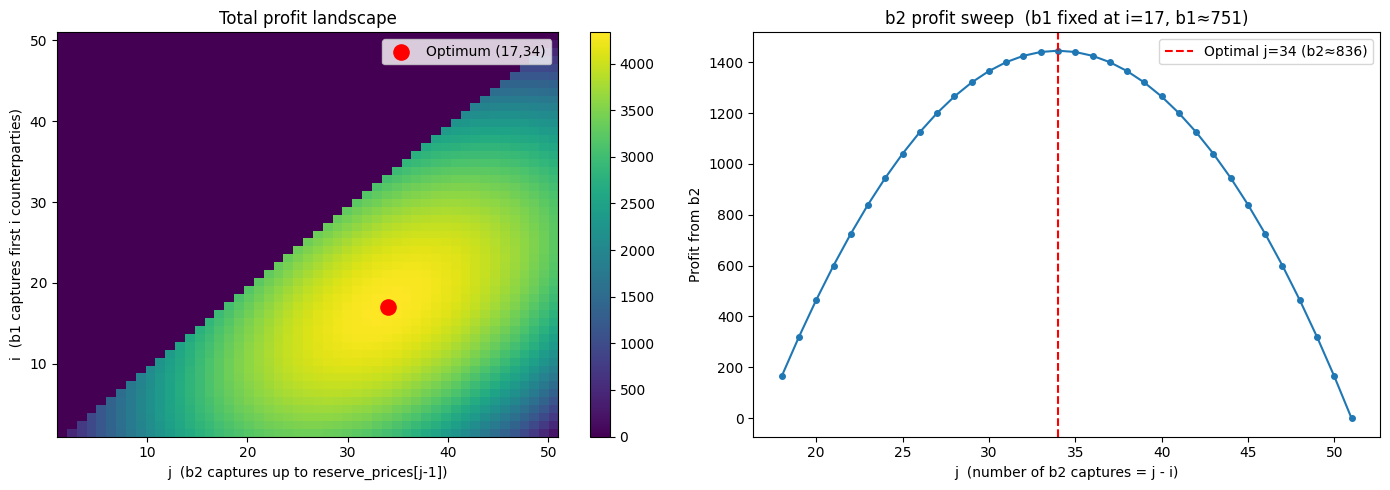


Nash equilibrium check: avg_b2=836, our b2=836
Penalty factor = 1.0000  (1.0 = no penalty)


In [3]:
# -----------------------------------------------------------------
# Visualise the profit landscape over (b1, b2)
# -----------------------------------------------------------------
grid = np.zeros((N + 1, N + 1))
for (i, j), v in results.items():
    grid[i, j] = v

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Heatmap
ax = axes[0]
im = ax.imshow(grid[1:, 1:], origin='lower', aspect='auto',
               extent=[1, N, 1, N], cmap='viridis')
ax.scatter(best_j, best_i, color='red', s=120, zorder=5, label=f'Optimum ({best_i},{best_j})')
ax.set_xlabel('j  (b2 captures up to reserve_prices[j-1])')
ax.set_ylabel('i  (b1 captures first i counterparties)')
ax.set_title('Total profit landscape')
plt.colorbar(im, ax=ax)
ax.legend()

# Profit vs b2 fixing b1 at optimum
ax2 = axes[1]
b2_profits = [(FAIR - reserve_prices[j - 1]) * (j - best_i) for j in range(best_i + 1, N + 1)]
j_vals = list(range(best_i + 1, N + 1))
ax2.plot(j_vals, b2_profits, marker='o', markersize=4)
ax2.axvline(best_j, color='red', linestyle='--', label=f'Optimal j={best_j} (b2≈{b2_opt+1})')
ax2.set_xlabel('j  (number of b2 captures = j - i)')
ax2.set_ylabel('Profit from b2')
ax2.set_title(f'b2 profit sweep  (b1 fixed at i={best_i}, b1≈{b1_opt+1})')
ax2.legend()
plt.tight_layout()
plt.show()

# -----------------------------------------------------------------
# Nash equilibrium check for b2
# At symmetric NE everyone bids b2 = b2_opt+1 → avg_b2 = b2_opt+1
# penalty factor = ((920-avg)/(920-b2))^3 = 1  → no penalty
# -----------------------------------------------------------------
avg_b2 = b2_opt + 1
our_b2 = b2_opt + 1
if our_b2 > avg_b2:
    penalty = 1.0
else:
    penalty = ((FAIR - avg_b2) / (FAIR - our_b2)) ** 3
print(f"\nNash equilibrium check: avg_b2={avg_b2}, our b2={our_b2}")
print(f"Penalty factor = {penalty:.4f}  (1.0 = no penalty)")


# Round 4:

 **Manual trading challenge: “Vanilla Just Isn’t Exotic Enough”**

As the Intarian economy evolved, trading expanded beyond standard calls and puts. In this round, you can trade `AETHER_CRYSTAL`, vanilla options with 2 and 3 week expiries, and several exotic derivatives written on the same underlying. 

Please note that a ‘week’ here refers to 5 trading days and that the ‘standard’ number of trading days per year is 252 (since some big exchanges are typically open 252 days per year). So “2 weeks” means 10 trading days, and “3 weeks” represents 15 trading days. For transparency purposes, this is how the days are computed on our end:

```python
TRADING_DAYS_PER_YEAR = 252
STEPS_PER_DAY = 4
STEPS_PER_YEAR = TRADING_DAYS_PER_YEAR * STEPS_PER_DAY

def weeks_to_years(weeks: float) -> float:
    # 5 business days per week, annualized to 252 trading days
    return (weeks * 5) / TRADING_DAYS_PER_YEAR

def steps_for_weeks(weeks: float) -> int:
    return int(round(weeks * 5 * STEPS_PER_DAY))
```

Thus, when you see "2 weeks", assume it means `2 * 5 * STEPS_PER_DAY` steps over 10 days.

Your objective is to construct positions that generate positive expected PnL. But be aware: unhedged exposure can lead to large losses, so risk management matters. The PnL is marked to the ‘fair’ value upon expiry, which is the average value of the product across 100 simulations. You should maximize the PnL on the products *as you hold them till expiry if you buy* (and short till expiry if you short). In other words, there is no buying or selling across days. You decide to buy/sell at t=0 (start of round 4) and hold it till expiry, at which point they are marked against their fair value. ***This means this challenge is completely standalone (there is NO relationship to Round 1)***.

All products are written on `AETHER_CRYSTAL`. You can trade the underlying, 2 week and 3 week vanilla calls and puts, and the following exotics:

**Chooser Option**

Expires in 3 weeks. After 2 weeks, the buyer chooses whether it becomes a call or a put, selecting whichever would be in the money at that time. It then behaves like a standard option for the final week until expiry.


**Binary Put Option**

Has an all-or-nothing payoff. If the underlying is below the strike at expiry, it pays the specified amount. Otherwise, it expires worthless.

**Knock-Out Put Option**

Behaves like a regular put unless the underlying ever trades below the knockout barrier before expiry. If the barrier is breached at any point, the option immediately becomes worthless.


You may buy or sell up to the displayed volume in each product. Note that the “contract size” is 3000 across all products, and is only used as a way to scale PnL proportionally to Rounds 3 and 5; think of it as a PnL multiplier on the PnL you make on the individual products (underlying, options) listed in the table. The prices you see are for each individual option.

Your final score is the average PnL across 100 simulations of the underlying.

The underlying `AETHER_CRYSTAL` is simulated using Geometric Brownian Motion with zero risk-neutral drift and fixed annualized volatility of 251%. Prices evolve on a discrete grid of 4 steps per trading day, assuming 252 trading days per year (see code above). There is no ‘continuous’ modeling under the hood that could trigger a knock-out; you should only consider these discrete points.

And remember, when payoffs become conditional, so does risk. Good luck!

**Note on “price” column**: this is purely cosmetic and should show the ‘investment cost’, but is unrelated to your PnL. It should in no way afffect your trading decision, and you can freely ignore it.

**Submit your orders**

Input your orders for the Aether Crystal and corresponding option contracts directly in the Manual Challenge Overview window and click the “Submit” button. You can re-submit new orders until the end of the trading round. When the round ends, the last submitted orders will be locked in and processed.

In [8]:
import pandas as pd
import numpy as np
data = [
    {
        "option": "AC",
        "expiry": "N/A",
        "size_bid": 200,
        "bid": 49.975,
        "ask": 50.025,
        "size_ask": 200,
        "buy/sell": np.nan,
        "volumne": np.nan,
        "price": 0.71,
        "description": "Aether Crystals (AETHER-CRYSTAL) are precision-grown minerals formed under controlled electromagnetic conditions. Each crystal stores and stabilizes ambient energy fluctuations, making them invaluable in advanced communication systems, architectural harmonics, and precision instrumentation."
    },
    {
        "option": "AC_50_P",
        "expiry": "T+21",
        "size_bid": 50,
        "bid": 12,
        "ask": 12.05,
        "size_ask": 50,
        "buy/sell": np.nan,
        "volumne": np.nan,
        "price": 2.71,
        "description": "AC_50_P is an Aether Crystal PUT Option contract with a Strike Price of 50 XIRECs and a Time To Expiry of 21 Solvenarian Days (starting from Round 1, on Intara)."
    },
    {
        "option": "AC_50_C",
        "expiry": "T+21",
        "size_bid": 50,
        "bid": 12,
        "ask": 12.05,
        "size_ask": 50,
        "buy/sell": np.nan,
        "volumne": np.nan,
        "price": -0.45,
        "description": "AC_50_C is an Aether Crystal CALL Option contract with a Strike Price of 50 XIRECs and a Time To Expiry of 21 Solvenarian Days (starting from Round 1, on Intara)."
    },
    {
        "option": "AC_35_P",
        "expiry": "T+21",
        "size_bid": 50,
        "bid": 4.33,
        "ask": 4.35,
        "size_ask": 50,
        "buy/sell": np.nan,
        "volumne": np.nan,
        "price": +0.42,
        "description": "AC_35_P is an Aether Crystal PUT Option contract with a Strike Price of 35 XIRECs and a Time To Expiry of 21 Solvenarian Days (starting from Round 1, on Intara)."
    },
    {
        "option": "AC_40_P",
        "expiry": "T+21",
        "size_bid": 50,
        "bid": 6.5,
        "ask": 6.55,
        "size_ask": 50,
        "buy/sell": np.nan,
        "volumne": np.nan,
        "price": 0.00,
        "description": "AC_40_P is an Aether Crystal PUT Option contract with a Strike Price of 40 XIRECs and a Time To Expiry of 21 Solvenarian Days (starting from Round 1, on Intara)."
    },
    {
        "option": "AC_45_P",
        "expiry": "T+21",
        "size_bid": 50,
        "bid": 9.05,
        "ask": 9.1,
        "size_ask": 50,
        "buy/sell": np.nan,
        "volumne": np.nan,
        "price": -0.48,
        "description": "AC_45_P is an Aether Crystal PUT Option contract with a Strike Price of 45 XIRECs and a Time To Expiry of 21 Solvenarian Days (starting from Round 1, on Intara)."
    },
    {
        "option": "AC_60_C",
        "expiry": "T+21",
        "size_bid": 50,
        "bid": 8.8,
        "ask": 8.85,
        "size_ask": 50,
        "buy/sell": np.nan,
        "volumne": np.nan,
        "price": +0.42,        
        "description": "AC_60_C is an Aether Crystal CALL Option contract with a Strike Price of 60 XIRECs and a Time To Expiry of 21 Solvenarian Days (starting from Round 1, on Intara)."
    },
    {
        "option": "AC_50_P_2",
        "expiry": "T+14",
        "size_bid": 50,
        "bid": 9.7,
        "ask": 9.75,
        "size_ask": 50,
        "buy/sell": np.nan,
        "volumne": np.nan,
        "price": +0.71,        
        "description": "AC_50_P_2 is an Aether Crystal PUT Option contract with a Strike Price of 50 XIRECs and a Time To Expiry of 14 Solvenarian Days (starting from Round 1, on Intara)."
    },
    {
        "option": "AC_50_C_2",
        "expiry": "T+14",
        "size_bid": 50,
        "bid": 9.7,
        "ask": 9.75,
        "size_ask": 50,
        "buy/sell": np.nan,
        "volumne": np.nan,
        "price": +0.71,        
        "description": "AC_50_C_2 is an Aether Crystal CALL Option contract with a Strike Price of 50 XIRECs and a Time To Expiry of 14 Solvenarian Days (starting from Round 1, on Intara)."
    },
    {
        "option": "AC_50_CO",
        "expiry": "T+14/21",
        "size_bid": 50,
        "bid": 22.2,
        "ask": 22.3,
        "size_ask": 50,
        "buy/sell": np.nan,
        "volumne": np.nan,
        "price": +0.71,        
        "description": "AC_50_CO is an Aether Crystal CHOOSER Option contract with a Strike Price of 50 XIRECs and a Time To Expiry of 21 Solvenarian Days (starting from Round 1, on Intara). After 14 Solvenarian Days, the buyer chooses the side (PUT or CALL). At that point, the contract automatically converts to the side that is “in the money”. After the remaining 7 Solvenarian Days, the contract expires like a standard PUT or CALL option."
    },
    {
        "option": "AC_40_BP",
        "expiry": "T+21",
        "size_bid": 50,
        "bid": 5,
        "ask": 5.1,
        "size_ask": 50,
        "buy/sell": np.nan,
        "volumne": np.nan,
        "price": +0.71,        
        "description": "AC_40_BP is an Aether Crystal BINARY PUT Option contract with a Strike Price of 40 XIRECs and a Time To Expiry of 21 Solvenarian Days (starting from Round 1, on Intara). If the value of the Aether Crystal at expiry is below 40 XIRECs, the contract pays a fixed amount of 10 XIRECs. If the value is at or above 40 XIRECs at expiry, the contract expires worthless."
    },
    {
        "option": "AC_45_KO",
        "expiry": "T+21",
        "size_bid": 500,
        "bid": 0.15,
        "ask": 0.175,
        "size_ask": 500,
        "buy/sell": np.nan,
        "volumne": np.nan,
        "price": +0.71,        
        "description": "AC_45_KO is an Aether Crystal KNOCK-OUT PUT Option contract with a Strike Price of 45 XIRECs, a Barrier Price of 35 XIRECs, and a Time To Expiry of 21 Solvenarian Days (starting from Round 1, on Intara). If the value of the Aether Crystal ever falls below 35 XIRECs, the contract is knocked out and expires worthless. If the barrier is never breached, the contract expires with the same payoff as a standard put option with a Strike Price of 45 XIRECs."
    }
]

df = pd.DataFrame(data)

# Pretty print
df

,option,expiry,size_bid,bid,ask,size_ask,buy/sell,volumne,price,description
0,AC,N/A,200,49.975,50.025,200,NaN,NaN,0.71,Aether Crystals (AETHER-CRYSTAL) are precision...
1,AC_50_P,T+21,50,12.000,12.050,50,NaN,NaN,2.71,AC_50_P is an Aether Crystal PUT Option contra...
2,AC_50_C,T+21,50,12.000,12.050,50,NaN,NaN,-0.45,AC_50_C is an Aether Crystal CALL Option contr...
3,AC_35_P,T+21,50,4.330,4.350,50,NaN,NaN,0.42,AC_35_P is an Aether Crystal PUT Option contra...
4,AC_40_P,T+21,50,6.500,6.550,50,NaN,NaN,0.00,AC_40_P is an Aether Crystal PUT Option contra...
5,AC_45_P,T+21,50,9.050,9.100,50,NaN,NaN,-0.48,AC_45_P is an Aether Crystal PUT Option contra...
6,AC_60_C,T+21,50,8.800,8.850,50,NaN,NaN,0.42,AC_60_C is an Aether Crystal CALL Option contr...
7,AC_50_P_2,T+14,50,9.700,9.750,50,NaN,NaN,0.71,AC_50_P_2 is an Aether Crystal PUT Option cont...
8,AC_50_C_2,T+14,50,9.700,9.750,50,NaN,NaN,0.71,AC_50_C_2 is an Aether Crystal CALL Option con...
9,AC_50_CO,T+14/21,50,22.200,22.300,50,NaN,NaN,0.71,AC_50_CO is an Aether Crystal CHOOSER Option c...


1. Implement Black-Scholes pricing for all vanilla options and verify which are mispriced
2. Price the chooser: use the analytical formula C(T₃w) + P(T₂w)
3. Price the binary put: straightforward N(-d₂) calculation
4. Monte Carlo the KO put: simulate 1 000 000 paths and check if barrier gets hit — compare to the 0.15 market price
5. Build positions on clear mispricings, keeping delta-neutral where possible (the PnL is scored against fair value over 100 runs, so variance matters)


**Strategy**: price every instrument with Black-Scholes (r = 0, σ = 251%), compare to market bid/ask, and trade anything with a meaningful edge.  
PnL is marked against the *average* payoff over 100 GBM simulations, so **expected edge = fair_value − execution_price**. Variance matters but can't be hedged (one-shot, hold to expiry).

Key formulas used:
- **Chooser** (r = 0): `V = Call(K, T_expiry) + Put(K, t_choice)` (exact analytical)
- **Binary put**: `V = payout × N(−d₂)`
- **Knock-out put**: closed-form is unreliable for discrete barriers → **Monte Carlo**

In [19]:
import numpy as np
import pandas as pd
from scipy.stats import norm

# ── Parameters ────────────────────────────────────────────────────────────────
S0  = 50.0   # AETHER_CRYSTAL mid-price (bid=49.975 / ask=50.025)
sig = 2.51   # annualized volatility = 251% (given)
# r = 0 (zero risk-neutral drift, stated in problem)

TRADING_DAYS_PER_YEAR = 252
STEPS_PER_DAY         = 4

def weeks_to_years(w):
    return (w * 5) / TRADING_DAYS_PER_YEAR

T2 = weeks_to_years(2)   # 2-week expiry = 10 trading days  → "T+14" labels
T3 = weeks_to_years(3)   # 3-week expiry = 15 trading days  → "T+21" labels

print(f"T2 = {T2*TRADING_DAYS_PER_YEAR:.0f} trading days  | σ√T2 = {sig*np.sqrt(T2):.4f}")
print(f"T3 = {T3*TRADING_DAYS_PER_YEAR:.0f} trading days  | σ√T3 = {sig*np.sqrt(T3):.4f}")

# ── Black-Scholes (r = 0) ─────────────────────────────────────────────────────
def bs_d1d2(S, K, T):
    sqT = np.sqrt(T)
    d1  = (np.log(S / K) + 0.5 * sig**2 * T) / (sig * sqT)
    return d1, d1 - sig * sqT

def bs_call(S, K, T):
    d1, d2 = bs_d1d2(S, K, T)
    return S * norm.cdf(d1) - K * norm.cdf(d2)

def bs_put(S, K, T):
    d1, d2 = bs_d1d2(S, K, T)
    return K * norm.cdf(-d2) - S * norm.cdf(-d1)

def chooser_fair(S, K, T_exp, t_choice):
    """
    Chooser: at t_choice holder picks whichever of call/put is ITM.
    Analytical formula (r = 0): V = C(K, T_exp) + P(K, t_choice)
    Derivation: max(C, P) = C + max(K−S(t*), 0)  [using P−C = K−S when r=0]
    Taking expectations → C(K, T_exp) + Put(K, t_choice)
    """
    return bs_call(S, K, T_exp) + bs_put(S, K, t_choice)

def binary_put_fair(S, K, T, payout=10.0):
    """Digital put: pays `payout` at T if S_T < K, else 0.  Value = payout * N(-d2)."""
    _, d2 = bs_d1d2(S, K, T)
    return payout * norm.cdf(-d2)

# ── Print all fair values ─────────────────────────────────────────────────────
print("\nInstrument      Type         K   Expiry   Fair value")
print("-" * 55)
vanilla_specs = [
    ("AC_50_P",   "put",  50, T3),
    ("AC_50_C",   "call", 50, T3),
    ("AC_35_P",   "put",  35, T3),
    ("AC_40_P",   "put",  40, T3),
    ("AC_45_P",   "put",  45, T3),
    ("AC_60_C",   "call", 60, T3),
    ("AC_50_P_2", "put",  50, T2),
    ("AC_50_C_2", "call", 50, T2),
]
for name, typ, K, T in vanilla_specs:
    fv = bs_call(S0, K, T) if typ == "call" else bs_put(S0, K, T)
    print(f"  {name:12s}  {typ:4s}  K={K:2d}  T+{int(T*TRADING_DAYS_PER_YEAR):2d}d   {fv:.4f}")

fv_co = chooser_fair(S0, 50, T3, T2)
fv_bp = binary_put_fair(S0, 40, T3, payout=10.0)
print(f"\n  {'AC_50_CO':12s}  chooser     K=50  T+14/21  {fv_co:.4f}")
print(f"    decomposition: C(50,T3)={bs_call(S0,50,T3):.4f}  +  P(50,T2)={bs_put(S0,50,T2):.4f}")
print(f"\n  {'AC_40_BP':12s}  binary_put  K=40  T+21     {fv_bp:.4f}")
print(f"    P(S_T<40) via N(-d2) = N({-bs_d1d2(S0,40,T3)[1]:.4f}) = {norm.cdf(-bs_d1d2(S0,40,T3)[1]):.4f}")
print(f"    fair = 10 × {norm.cdf(-bs_d1d2(S0,40,T3)[1]):.4f} = {fv_bp:.4f}")


T2 = 10 trading days  | σ√T2 = 0.5000
T3 = 15 trading days  | σ√T3 = 0.6124

Instrument      Type         K   Expiry   Fair value
-------------------------------------------------------
  AC_50_P       put   K=50  T+15d   12.0269
  AC_50_C       call  K=50  T+15d   12.0269
  AC_35_P       put   K=35  T+15d   4.3361
  AC_40_P       put   K=40  T+15d   6.5095
  AC_45_P       put   K=45  T+15d   9.0889
  AC_60_C       call  K=60  T+15d   8.7918
  AC_50_P_2     put   K=50  T+10d   9.8707
  AC_50_C_2     call  K=50  T+10d   9.8707

  AC_50_CO      chooser     K=50  T+14/21  21.8977
    decomposition: C(50,T3)=12.0269  +  P(50,T2)=9.8707

  AC_40_BP      binary_put  K=40  T+21     4.7679
    P(S_T<40) via N(-d2) = N(-0.0582) = 0.4768
    fair = 10 × 0.4768 = 4.7679


In [20]:
def ko_put_mc(S0, K, barrier, T, n_sims=1_000_000, seed=42):
    """
    Down-and-out put: discrete monitoring at every step on the
    STEPS_PER_DAY × trading-day grid (matches problem's simulation grid).

    Payoff = max(K − S_T, 0) if min(S_t) >= barrier, else 0.
    Returns (fair_value, 95pct_CI_half_width, knock_out_probability)
    """
    np.random.seed(seed)
    n_steps = int(round(T * TRADING_DAYS_PER_YEAR * STEPS_PER_DAY))
    dt      = T / n_steps
    drift   = -0.5 * sig**2 * dt          # r = 0
    vol_dt  = sig * np.sqrt(dt)

    Z      = np.random.standard_normal((n_sims, n_steps))
    paths  = np.exp(np.log(S0) + np.cumsum(drift + vol_dt * Z, axis=1))

    alive   = paths.min(axis=1) >= barrier   # True = barrier never breached
    S_T     = paths[:, -1]
    payoffs = np.maximum(K - S_T, 0.0) * alive

    fv = payoffs.mean()
    ci = 1.96 * payoffs.std() / np.sqrt(n_sims)
    return fv, ci, (~alive).mean()

# ── Run simulation ────────────────────────────────────────────────────────────
print("Running 1 000 000 path Monte Carlo for AC_45_KO ...")
fv_ko, ci_ko, ko_prob = ko_put_mc(S0=50, K=45, barrier=35, T=T3)

vanilla_45 = bs_put(S0, 45, T3)

print(f"\n  Vanilla put  (K=45, T3)       = {vanilla_45:.4f}")
print(f"  Knock-out probability         = {ko_prob:.2%}  (barrier=35 hit at any step)")
print(f"  KO put fair value  (MC)       = {fv_ko:.4f}  ± {ci_ko:.4f}  (95% CI)")
print(f"  Value removed by barrier      = {vanilla_45 - fv_ko:.4f}")
print()
print(f"  Market  bid = 0.1500  |  ask = 0.1750")
print(f"  Edge if BUY  (pay ask 0.1750) : {fv_ko - 0.1750:+.4f}  per contract")
print(f"  Edge if SELL (get bid 0.1500) : {0.1500 - fv_ko:+.4f}  per contract")


Running 1 000 000 path Monte Carlo for AC_45_KO ...

  Vanilla put  (K=45, T3)       = 9.0889
  Knock-out probability         = 61.48%  (barrier=35 hit at any step)
  KO put fair value  (MC)       = 0.2067  ± 0.0021  (95% CI)
  Value removed by barrier      = 8.8822

  Market  bid = 0.1500  |  ask = 0.1750
  Edge if BUY  (pay ask 0.1750) : +0.0317  per contract
  Edge if SELL (get bid 0.1500) : -0.0567  per contract


In [ ]:
CONTRACT_SIZE = 3000   # PnL multiplier (same for all products)
MIN_EDGE      = 0.03   # minimum per-contract edge to trade (lowered from 0.05 to capture KO put)

# (name, type, K, T_years, bid, ask, size_bid, size_ask, fair_value)
instruments = [
    ("AC_50_P",   "put",        50, T3,   12.00, 12.05,  50,  50, bs_put(S0, 50, T3)),
    ("AC_50_C",   "call",       50, T3,   12.00, 12.05,  50,  50, bs_call(S0, 50, T3)),
    ("AC_35_P",   "put",        35, T3,    4.33,  4.35,  50,  50, bs_put(S0, 35, T3)),
    ("AC_40_P",   "put",        40, T3,    6.50,  6.55,  50,  50, bs_put(S0, 40, T3)),
    ("AC_45_P",   "put",        45, T3,    9.05,  9.10,  50,  50, bs_put(S0, 45, T3)),
    ("AC_60_C",   "call",       60, T3,    8.80,  8.85,  50,  50, bs_call(S0, 60, T3)),
    ("AC_50_P_2", "put",        50, T2,    9.70,  9.75,  50,  50, bs_put(S0, 50, T2)),
    ("AC_50_C_2", "call",       50, T2,    9.70,  9.75,  50,  50, bs_call(S0, 50, T2)),
    ("AC_50_CO",  "chooser",    50, None,  22.20, 22.30,  50,  50, fv_co),
    ("AC_40_BP",  "binary_put", 40, T3,    5.00,  5.10,  50,  50, fv_bp),
    ("AC_45_KO",  "ko_put",     45, T3,    0.15,  0.175, 500, 500, fv_ko),
]

# ── Build summary table ───────────────────────────────────────────────────────
rows = []
for name, typ, K, T_opt, bid, ask, sz_b, sz_a, fair in instruments:
    e_buy  = fair - ask
    e_sell = bid  - fair
    if   e_buy  >= MIN_EDGE: action, qty, price, edge = "BUY",  sz_a, ask, e_buy
    elif e_sell >= MIN_EDGE: action, qty, price, edge = "SELL", sz_b, bid, e_sell
    else:                    action, qty, price, edge = "PASS", 0,   0.0, 0.0
    rows.append(dict(option=name, type=typ, bid=bid, ask=ask,
                     fair=round(fair, 4),
                     edge_buy=round(e_buy, 4), edge_sell=round(e_sell, 4),
                     action=action, qty=qty,
                     exp_pnl=round(edge * qty * CONTRACT_SIZE)))

df_out = pd.DataFrame(rows)[["option","type","bid","ask","fair",
                              "edge_buy","edge_sell","action","qty","exp_pnl"]]
print(df_out.to_string(index=False))
total_pnl = sum(r["exp_pnl"] for r in rows)
print(f"\n  Total expected PnL (marked at fair value) = {total_pnl:+,.0f}")

# ── Net delta check (numerical bump-and-reprice) ──────────────────────────────
print("\n── Net delta (Δ per unit, contribution = sign × qty × Δ) ──")
net_delta = 0.0
dS = 0.01

def reprice(name, typ, K, T_opt):
    T_use = T_opt if T_opt is not None else T3
    if   typ == "call":       return bs_call(S0, K, T_use), bs_call(S0+dS, K, T_use), bs_call(S0-dS, K, T_use)
    elif typ == "put":        return bs_put(S0, K, T_use),  bs_put(S0+dS, K, T_use),  bs_put(S0-dS, K, T_use)
    elif typ == "chooser":    return (fv_co,
                                     chooser_fair(S0+dS, 50, T3, T2),
                                     chooser_fair(S0-dS, 50, T3, T2))
    elif typ == "binary_put": return (fv_bp,
                                     binary_put_fair(S0+dS, K, T_use),
                                     binary_put_fair(S0-dS, K, T_use))
    else:                     # ko_put: approximate with vanilla × P(alive)
        p_alive = 1 - ko_prob
        return (fv_ko,
                bs_put(S0+dS, K, T_use) * p_alive,
                bs_put(S0-dS, K, T_use) * p_alive)

for row, (name, typ, K, T_opt, *_rest) in zip(rows, instruments):
    if row["action"] == "PASS":
        continue
    _, fu, fd = reprice(name, typ, K, T_opt)
    delta  = (fu - fd) / (2 * dS)
    sign   = +1 if row["action"] == "BUY" else -1
    contrib = sign * row["qty"] * delta
    net_delta += contrib
    print(f"  {row['action']:4s} {name:12s}  qty={row['qty']:3d}  Δ/contract={delta:+.4f}  contrib={contrib:+.2f}")

print(f"\n  Net Δ ≈ {net_delta:+.2f}  (units of underlying)")
print(f"  Note: delta hedging costs bid-ask spread on AC (0.025/unit) → reduces expected PnL.")
print(f"  Since scoring = average PnL over 100 sims, expected value maximization dominates.")
if abs(net_delta) <= 10:
    print("  ✓ Portfolio is approximately delta-neutral — no hedge needed.")
else:
    side = "BUY" if net_delta < 0 else "SELL"
    hedge_qty = min(200, abs(int(round(net_delta))))
    hedge_cost = hedge_qty * 0.025 * CONTRACT_SIZE
    print(f"  → Large delta exposure. Optional hedge: {side} {hedge_qty} AC at ~50")
    print(f"    (costs ≈ {hedge_cost:,.0f} in expected PnL via bid-ask spread, reduces variance)")


   option       type   bid    ask    fair  edge_buy  edge_sell action  qty  exp_pnl
  AC_50_P        put 12.00 12.050 12.0269   -0.0231    -0.0269   PASS    0        0
  AC_50_C       call 12.00 12.050 12.0269   -0.0231    -0.0269   PASS    0        0
  AC_35_P        put  4.33  4.350  4.3361   -0.0139    -0.0061   PASS    0        0
  AC_40_P        put  6.50  6.550  6.5095   -0.0405    -0.0095   PASS    0        0
  AC_45_P        put  9.05  9.100  9.0889   -0.0111    -0.0389   PASS    0        0
  AC_60_C       call  8.80  8.850  8.7918   -0.0582     0.0082   PASS    0        0
AC_50_P_2        put  9.70  9.750  9.8707    0.1207    -0.1707    BUY   50    18106
AC_50_C_2       call  9.70  9.750  9.8707    0.1207    -0.1707    BUY   50    18106
 AC_50_CO    chooser 22.20 22.300 21.8977   -0.4023     0.3023   SELL   50    45351
 AC_40_BP binary_put  5.00  5.100  4.7679   -0.3321     0.2321   SELL   50    34808
 AC_45_KO     ko_put  0.15  0.175  0.2067    0.0317    -0.0567   PASS    0  